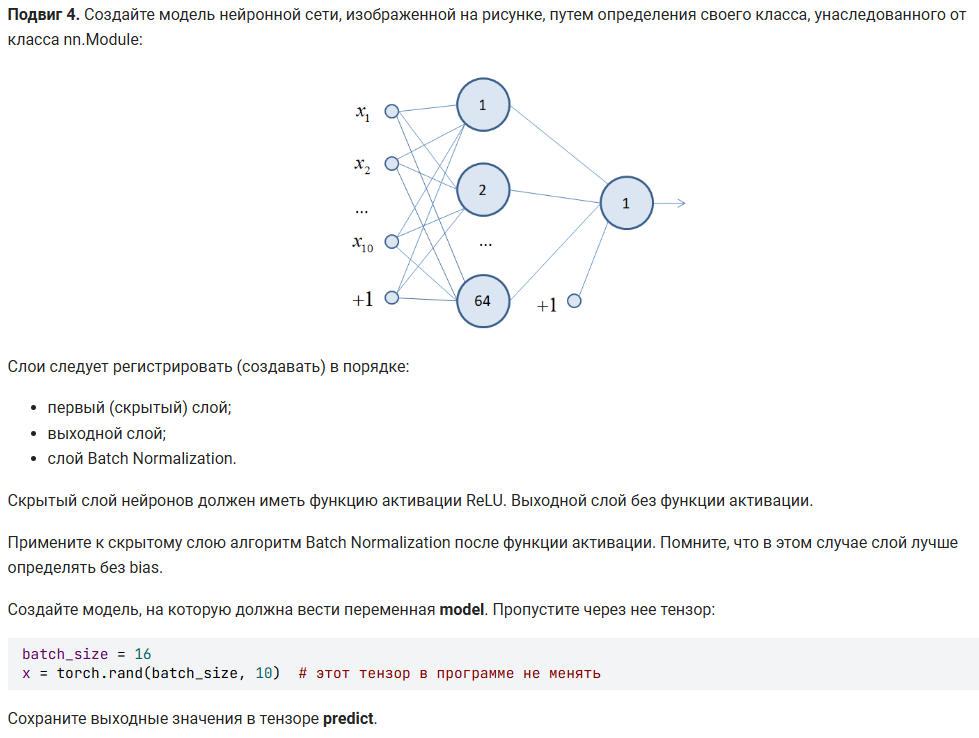

In [28]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели (важно именно здесь)
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(10, 64, bias=False)
        self.layer2 = nn.Linear(64, 1)
        self.bn = nn.BatchNorm1d(64)
        self.activation = nn.ReLU()
        
    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.bn(x)
        x = self.layer2(x)
        return x
        
model = MyModel() # здесь создавайте объект модели
model.eval() # обязательно, так как используется слой batchnorm

batch_size = 16
x = torch.rand(batch_size, 10)  # этот тензор в программе не менять

# здесь продолжайте программу
predict = model(x)
predict

tensor([[0.1535],
        [0.1106],
        [0.0800],
        [0.1085],
        [0.1205],
        [0.1843],
        [0.1853],
        [0.1592],
        [0.1677],
        [0.1367],
        [0.0788],
        [0.2012],
        [0.2390],
        [0.2087],
        [0.1892],
        [0.1610]], grad_fn=<AddmmBackward0>)

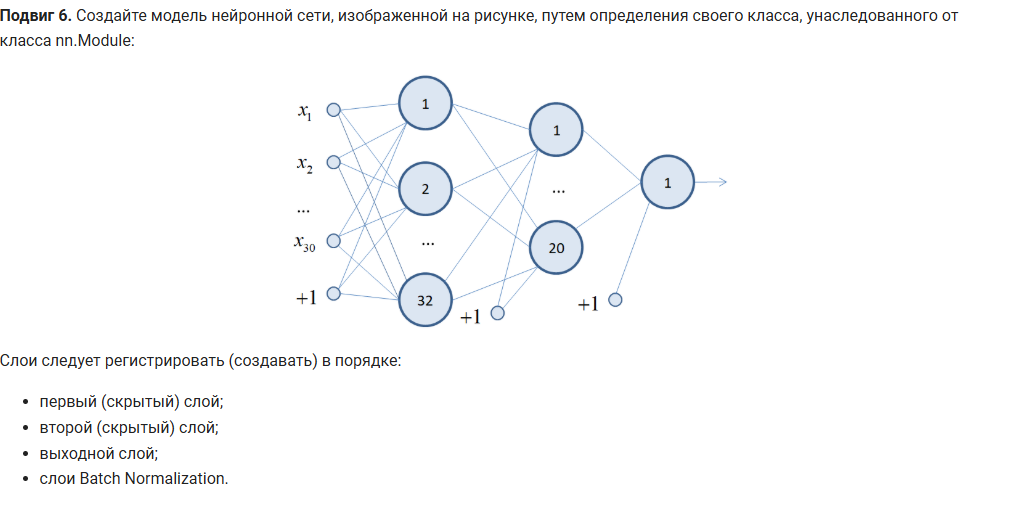

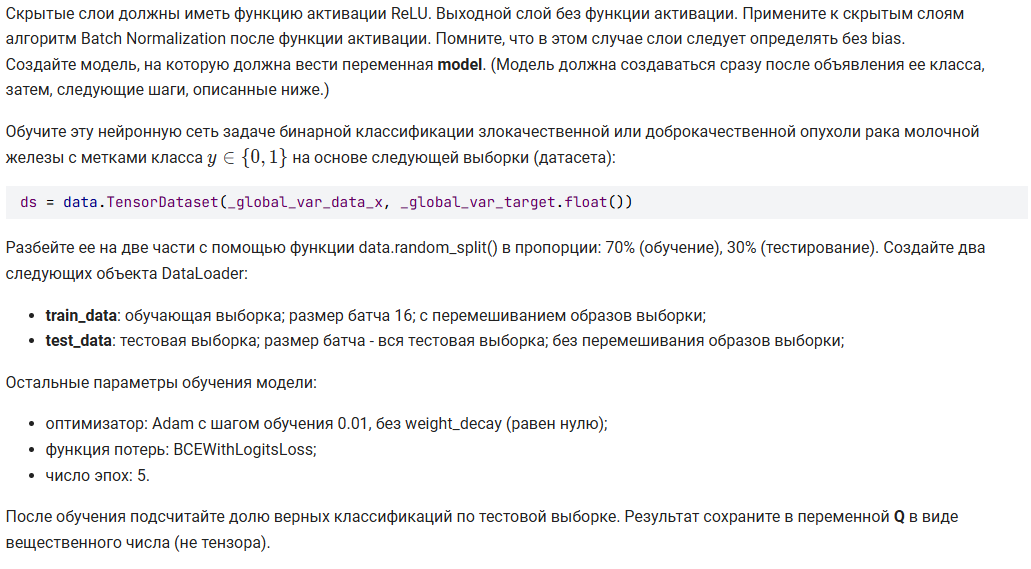

In [29]:
import torch
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

_global_var_data_x = torch.tensor(data.data, dtype=torch.float32)
_global_var_target = torch.tensor(data.target, dtype=torch.int64)

In [42]:
_global_var_data_x.shape

torch.Size([569, 30])

In [75]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim

class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(30, 32, bias=False)
        self.layer2 = nn.Linear(32, 20, bias=False)
        self.layer3 = nn.Linear(20, 1)
        self.bn1 = nn.BatchNorm1d(32)
        self.bn2 = nn.BatchNorm1d(20)
        self.activation = nn.ReLU()

    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.bn1(x)
        x = self.layer2(x)
        x = self.activation(x)
        x = self.bn2(x)
        x = self.layer3(x)
        return x

model = MyModel()

ds = data.TensorDataset(_global_var_data_x, _global_var_target.float())

train, test = data.random_split(ds, [0.7, 0.3])

train_data = data.DataLoader(train, batch_size=16, shuffle=True)
test_data = data.DataLoader(test, batch_size=len(test), shuffle=False)

optimizer = optim.Adam(model.parameters(), lr=0.01, weight_decay=0)
loss_func = nn.BCEWithLogitsLoss()

n_epochs = 5


for e in range(n_epochs):
    model.train()
    for x_train, y_train in train_data:
        optimizer.zero_grad()
        predict = model(x_train).squeeze(1)
        # print(predict.shape, y_train.shape)
        # print(predict, y_train)
        loss = loss_func(predict, y_train)
        loss.backward()
        optimizer.step()


x_test, y_test = next(iter(test_data))

model.eval()
probs = torch.sigmoid(model(x_test)).squeeze(1)
pred = (probs > 0.5).float()
Q = torch.mean((pred==y_test).float()).item()
Q

  

0.5346021056175232

In [59]:
y_test.dtype


torch.float32